# BT4012 Group 6 — Data Sampling & Cleaning

**Dataset:** Home Credit Default Risk (Kaggle). 7 relational tables, 307,511 labelled applicants.

This notebook prepares **one shared, clean dataset** for all three experiments, plus the reference files that the
Exp2 and Exp3 evaluation files use. Feature engineering is left to each experiment owner.

| Part | What it does | Output |
|---|---|---|
| 1. Setup | imports, paths, settings | — |
| 2. Explore | size of each table, previous applications per applicant | — |
| 3. Sample + filter | stratified sample of 100,000 applicants, then **filter every table to those applicants** | — |
| 4. Split | train / val / test (70/15/15) + dev flag | `clean_data/splits.csv` |
| 5. Clean | rule-based fixes for each table | `clean_data/*.parquet`, `cleaning_report.csv` |
| 6. Reference files | history segments (Exp2) and rule-based red flags (Exp3) | `Exp_2/history_segments.parquet`, `Exp_3/data/red_flag*` |

Run from the project root, with the raw Kaggle CSVs in `home-credit-default-risk/`. The cleaned tables are written to
`clean_data/`; the project `README.md` explains every file.

## Part 1 — Setup

In [1]:
import gc
import json
import os
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

DATA_DIR = Path("home-credit-default-risk")   # raw Kaggle CSVs
CLEAN = Path("clean_data")                     # hand-over: cleaned tables + split
CLEAN.mkdir(parents=True, exist_ok=True)

SEED = 42
SAMPLE_N = 100_000       # applicants in the shared subset
DEV_FRAC = 0.20          # share of each split flagged is_dev (for quick experiments)
DAYS_SENTINEL = 365243   # Home Credit placeholder meaning "no date"
T0 = time.time()

TABLES = {  # file name -> short name used for outputs
    "application_train": "application", "bureau": "bureau", "bureau_balance": "bureau_balance",
    "previous_application": "previous_application", "installments_payments": "installments",
    "POS_CASH_balance": "pos_cash", "credit_card_balance": "credit_card",
}


def downcast(df):
    """Shrink memory: 64-bit numbers -> 32-bit, text -> category."""
    for c in df.columns:
        s = df[c]
        if pd.api.types.is_float_dtype(s):
            df[c] = s.astype("float32")
        elif pd.api.types.is_integer_dtype(s):
            df[c] = pd.to_numeric(s, downcast="integer")
        elif not pd.api.types.is_bool_dtype(s):
            df[c] = s.astype("category")
    return df.copy()


def load(name, usecols=None):
    df = pd.read_csv(DATA_DIR / f"{name}.csv", usecols=usecols, engine="pyarrow")
    return downcast(df)

## Part 2 — Explore
One applicant (`SK_ID_CURR`) links to many historical records:
```
application_train  (1 row per applicant, has TARGET)
├── bureau                 loans at other lenders         ── bureau_balance  (monthly status, via SK_ID_BUREAU)
└── previous_application   past Home Credit applications
    ├── installments_payments   each scheduled repayment vs actual payment
    ├── POS_CASH_balance        monthly POS / cash-loan snapshots
    └── credit_card_balance     monthly credit-card snapshots
```
The team suggested stratifying the sample on the **number of previous applications** per applicant. The table below
shows why: the default rate rises with history length (6.0% for 0 vs 9.7% for 10+). We therefore stratify on
**TARGET × previous-application bucket** together, which preserves both the default rate and the history mix.

Applicants: 307,511 | default rate (TARGET=1): 8.07%


,applicants,default_rate,share
previous applications,,,
0,"16,454",5.96%,5.4%
1,"52,533",8.38%,17.1%
2,"45,799",7.86%,14.9%
3,"40,014",7.81%,13.0%
4,"32,922",7.56%,10.7%
5,"26,638",7.88%,8.7%
6,"21,073",7.95%,6.9%
7,"16,384",8.23%,5.3%
8,"12,785",8.31%,4.2%


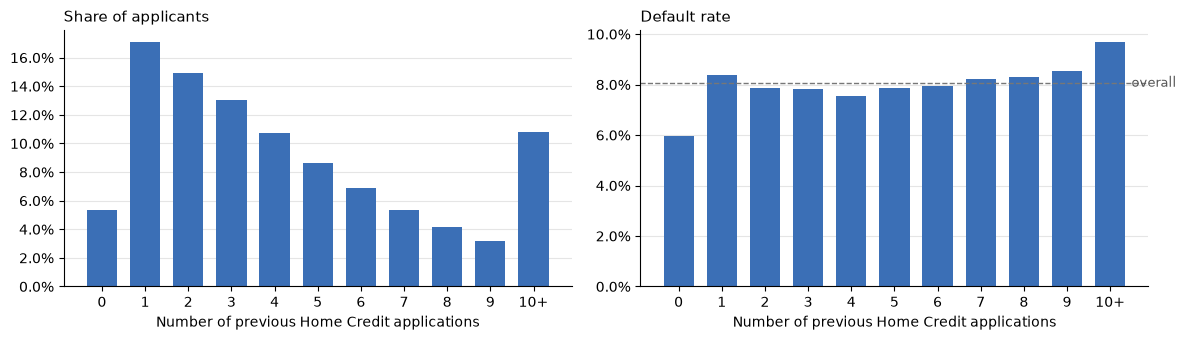

In [2]:
app = load("application_train")
assert app["SK_ID_CURR"].is_unique
n_prev = load("previous_application", usecols=["SK_ID_CURR"])["SK_ID_CURR"].value_counts()
app["N_PREV_APPS"] = app["SK_ID_CURR"].map(n_prev).fillna(0).astype("int16")
app["PREV_BUCKET"] = app["N_PREV_APPS"].clip(upper=10).astype("int8")   # 10 means "10 or more"
print(f"Applicants: {len(app):,} | default rate (TARGET=1): {app['TARGET'].mean():.2%}")

explore = (app.groupby("PREV_BUCKET")
              .agg(applicants=("SK_ID_CURR", "size"), default_rate=("TARGET", "mean"))
              .assign(share=lambda d: d["applicants"] / len(app)))
explore.index = [str(i) if i < 10 else "10+" for i in explore.index]
explore.index.name = "previous applications"
display(explore.style.format({"applicants": "{:,}", "default_rate": "{:.2%}", "share": "{:.1%}"}))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, col, title, fmt in [(axes[0], "share", "Share of applicants", "{:.0%}"),
                            (axes[1], "default_rate", "Default rate", "{:.1%}")]:
    ax.bar(explore.index, explore[col], color="#3B6FB6", width=0.7)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("Number of previous Home Credit applications")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: fmt.format(v)))
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
    ax.set_axisbelow(True)
axes[1].axhline(app["TARGET"].mean(), color="#777777", linestyle="--", linewidth=1)
axes[1].text(10.4, app["TARGET"].mean(), " overall", va="center", fontsize=9, color="#555555")
plt.tight_layout()
plt.show()

## Part 3 — Sample + filter all tables
**Step 1, sample applicants.** Pick 100,000 `SK_ID_CURR` from `application_train`, stratified on
TARGET × previous-application bucket.

**Step 2, filter every other table to those applicants** (this is what "apply the filter to all datasets" means):
* `bureau`, `previous_application`, `installments_payments`, `POS_CASH_balance`, `credit_card_balance`: keep rows
  whose `SK_ID_CURR` is in the sample.
* `bureau_balance` has no `SK_ID_CURR`, so keep rows whose `SK_ID_BUREAU` survived the bureau filter.

Sampling *applicants* rather than *rows* keeps each sampled applicant's history complete. Sampling 30% of each
table independently would leave applicants with half their repayment history missing.

In [3]:
# Step 1: stratified sample of applicants
strata = app["TARGET"].astype(str) + "_" + app["PREV_BUCKET"].astype(str)
sample_ids, _ = train_test_split(app["SK_ID_CURR"], train_size=SAMPLE_N, stratify=strata, random_state=SEED)
in_sample = app["SK_ID_CURR"].isin(sample_ids)

# Validate: the subset should match the full data, including on variables we did NOT stratify on.
# KS statistic = largest gap between the two distributions (< 0.01 means no practical difference).
app["N_BUREAU_RECORDS"] = app["SK_ID_CURR"].map(load("bureau", usecols=["SK_ID_CURR"])["SK_ID_CURR"].value_counts()).fillna(0)
rows = []
for col in ["TARGET", "N_PREV_APPS", "N_BUREAU_RECORDS", "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY",
            "EXT_SOURCE_2", "EXT_SOURCE_3", "DAYS_BIRTH"]:
    full_v, sub_v = app[col].dropna(), app.loc[in_sample, col].dropna()
    rows.append({"variable": col, "full_data_mean": full_v.mean(), "subset_mean": sub_v.mean(),
                 "KS_stat": ks_2samp(full_v, sub_v).statistic})
sample_check = pd.DataFrame(rows).set_index("variable")
display(sample_check.style.format({"full_data_mean": "{:,.4f}", "subset_mean": "{:,.4f}", "KS_stat": "{:.4f}"}))
assert sample_check["KS_stat"].max() < 0.02, "subset differs from the full population"

app = app.loc[in_sample].drop(columns=["N_BUREAU_RECORDS"]).reset_index(drop=True)
SAMPLE = set(app["SK_ID_CURR"])
print(f"Sampled {len(app):,} applicants | default rate {app['TARGET'].mean():.3%}")

,full_data_mean,subset_mean,KS_stat
variable,,,
TARGET,0.0807,0.0807,0.0000
N_PREV_APPS,4.5972,4.5899,0.0008
N_BUREAU_RECORDS,4.7651,4.7613,0.0021
AMT_INCOME_TOTAL,"168,797.9219","168,358.2500",0.0026
AMT_CREDIT,"599,026.0000","599,296.0625",0.0021
AMT_ANNUITY,"27,108.5742","27,047.8359",0.0021
EXT_SOURCE_2,0.5144,0.5143,0.0015
EXT_SOURCE_3,0.5109,0.5100,0.0033
DAYS_BIRTH,"-16,036.9951","-16,039.7467",0.0020


Sampled 100,000 applicants | default rate 8.073%


In [4]:
# Step 2: filter every table to the sampled applicants
tables = {"application": app}
filter_log = [{"table": "application_train", "rows_before": len(in_sample), "rows_after": len(app)}]

for file in ["bureau", "previous_application", "installments_payments", "POS_CASH_balance", "credit_card_balance"]:
    df = load(file)
    kept = df[df["SK_ID_CURR"].isin(SAMPLE)].reset_index(drop=True)
    filter_log.append({"table": file, "rows_before": len(df), "rows_after": len(kept)})
    tables[TABLES[file]] = kept
    del df; gc.collect()

bb = load("bureau_balance")                               # no SK_ID_CURR: filter through the kept bureau loans
kept_bureau = tables["bureau"][["SK_ID_BUREAU", "SK_ID_CURR"]]
bb_kept = bb.merge(kept_bureau, on="SK_ID_BUREAU", how="inner")   # also attaches SK_ID_CURR for convenience
filter_log.append({"table": "bureau_balance", "rows_before": len(bb), "rows_after": len(bb_kept)})
tables["bureau_balance"] = bb_kept
del bb; gc.collect()

filter_log = pd.DataFrame(filter_log).set_index("table")
filter_log["kept"] = filter_log["rows_after"] / filter_log["rows_before"]
display(filter_log.style.format({"rows_before": "{:,}", "rows_after": "{:,}", "kept": "{:.1%}"}))

# Every remaining row must belong to a sampled applicant
for name, df in tables.items():
    assert df["SK_ID_CURR"].isin(SAMPLE).all(), name
print("All tables contain only sampled applicants.")

,rows_before,rows_after,kept
table,,,
application_train,"307,511","100,000",32.5%
bureau,"1,716,428","476,130",27.7%
previous_application,"1,670,214","458,993",27.5%
installments_payments,"13,605,401","3,776,583",27.8%
POS_CASH_balance,"10,001,358","2,773,426",27.7%
credit_card_balance,"3,840,312","1,062,183",27.7%
bureau_balance,"27,299,925","4,812,174",17.6%


All tables contain only sampled applicants.


## Part 4 — Train / validation / test split
The 100k applicants are split **once**, 70/15/15, stratified the same way. **All experiments must use this split**:
* train: fit models, and fit anything learned from data (imputation, scaling, thresholds)
* val: tune hyper-parameters and choose the decision threshold
* test: report final results only (Exp3's investigated applicants also come from here)

`is_dev` marks a stratified 20% of each split for quick trial runs. Final results use the whole split.

In [5]:
strata = app["TARGET"].astype(str) + "_" + app["PREV_BUCKET"].astype(str)
id_trval, id_test = train_test_split(app["SK_ID_CURR"], test_size=0.15, stratify=strata, random_state=SEED)
trval = app["SK_ID_CURR"].isin(id_trval)
id_train, id_val = train_test_split(app.loc[trval, "SK_ID_CURR"], test_size=0.15 / 0.85,
                                    stratify=strata[trval], random_state=SEED)

splits = app[["SK_ID_CURR", "TARGET", "N_PREV_APPS", "PREV_BUCKET"]].copy()
splits["split"] = np.select([splits["SK_ID_CURR"].isin(id_train), splits["SK_ID_CURR"].isin(id_val)],
                            ["train", "val"], default="test")
splits["is_dev"] = False
for s in ["train", "val", "test"]:
    part = splits[splits["split"] == s]
    dev_ids, _ = train_test_split(part["SK_ID_CURR"], train_size=DEV_FRAC, stratify=strata[part.index],
                                  random_state=SEED)
    splits.loc[splits["SK_ID_CURR"].isin(dev_ids), "is_dev"] = True
splits = splits.sort_values("SK_ID_CURR").reset_index(drop=True)
splits.to_csv(CLEAN / "splits.csv", index=False)

summary = splits.groupby("split").agg(applicants=("SK_ID_CURR", "size"), default_rate=("TARGET", "mean"),
                                      dev_applicants=("is_dev", "sum"))
display(summary.style.format({"applicants": "{:,}", "dev_applicants": "{:,}", "default_rate": "{:.3%}"}))
gap = (summary["default_rate"] - splits["TARGET"].mean()).abs().max()
assert gap < 0.002, "default rate differs across splits"
print(f"Split is balanced: default rates differ by at most {gap:.4%}")

,applicants,default_rate,dev_applicants
split,,,
test,"15,000",8.073%,"3,000"
train,"69,999",8.072%,"13,999"
val,"15,001",8.079%,"3,000"


Split is balanced: default rates differ by at most 0.0065%


## Part 5 — Clean each table
Cleaning only fixes **data errors** with fixed rules. Nothing is learned from the data, so cleaning cannot leak
information from val/test into training. Missing values are **left as NaN**; how to fill them is a modelling choice
each experiment makes using train data. Every rule and the number of rows it touched is recorded in
`cleaning_report.csv`.

In [6]:
report = []


def log(table, rule, n):
    report.append({"table": table, "rule": rule, "rows_affected": int(n)})


def to_missing(df, table, col, mask, rule):
    """Set df.loc[mask, col] to NaN (casting int columns to float first) and log it."""
    if pd.api.types.is_integer_dtype(df[col]):
        df[col] = df[col].astype("float32")
    log(table, f"{col}: {rule} -> NaN", mask.sum())
    df.loc[mask, col] = np.nan


def drop_categories(df, table, col, values):
    """Placeholder categories such as 'XNA' (not available) / 'XAP' (not applicable) -> NaN."""
    n = df[col].isin(values).sum()
    if n:
        df[col] = df[col].cat.remove_categories([v for v in values if v in df[col].cat.categories])
    log(table, f"{col}: {values} -> NaN", n)

### 5.1 application
| Problem | Fix |
|---|---|
| `DAYS_EMPLOYED = 365243` (placeholder, mostly pensioners) | NaN + new flag `DAYS_EMPLOYED_ANOM` |
| `CODE_GENDER = 'XNA'`, `NAME_FAMILY_STATUS = 'Unknown'`, `ORGANIZATION_TYPE = 'XNA'` | NaN |
| Income above 10 million (e.g. one applicant reports 117M) | NaN + flag `INCOME_OUTLIER` |
| Any `DAYS_*` > 0 (dates are counted backwards from the application, so must be ≤ 0) | NaN |

In [7]:
t = "application"
a = tables[t]
a["DAYS_EMPLOYED_ANOM"] = (a["DAYS_EMPLOYED"] == DAYS_SENTINEL).astype("int8")
to_missing(a, t, "DAYS_EMPLOYED", a["DAYS_EMPLOYED"] == DAYS_SENTINEL, "placeholder 365243")
drop_categories(a, t, "CODE_GENDER", ["XNA"])
drop_categories(a, t, "NAME_FAMILY_STATUS", ["Unknown"])
drop_categories(a, t, "ORGANIZATION_TYPE", ["XNA"])
a["INCOME_OUTLIER"] = (a["AMT_INCOME_TOTAL"] > 1e7).astype("int8")
to_missing(a, t, "AMT_INCOME_TOTAL", a["AMT_INCOME_TOTAL"] > 1e7, "> 10 million")
for c in [c for c in a.columns if c.startswith("DAYS_") and c != "DAYS_EMPLOYED_ANOM"]:
    if (a[c] > 0).any():
        to_missing(a, t, c, a[c] > 0, "positive (date after application)")
a = a.drop(columns=["N_PREV_APPS", "PREV_BUCKET"])   # helper columns from sampling (kept in splits.csv)
tables[t] = a

### 5.2 bureau and bureau_balance (loans at other lenders)
| Problem | Fix |
|---|---|
| `DAYS_CREDIT`, `DAYS_ENDDATE_FACT`, `DAYS_CREDIT_UPDATE` > 0, or any date more than 100 years ago | NaN |
| Negative debt (overpayment) | 0 |
| Negative credit limit | NaN |
| `bureau_balance.STATUS` is text: `0` on time, `1`–`5` increasingly late, `C` closed, `X` unknown | add numeric `STATUS_DPD` (0–5, NaN for C/X) and flags `IS_CLOSED`, `IS_UNKNOWN` |

`DAYS_CREDIT_ENDDATE` may legitimately be positive (a loan ending in the future).

In [8]:
t = "bureau"
b = tables[t]
for c in ["DAYS_CREDIT", "DAYS_ENDDATE_FACT", "DAYS_CREDIT_UPDATE"]:
    to_missing(b, t, c, (b[c] > 0) | (b[c] < -36500), "positive or > 100 years ago")
to_missing(b, t, "DAYS_CREDIT_ENDDATE", b["DAYS_CREDIT_ENDDATE"] < -36500, "> 100 years ago")
log(t, "AMT_CREDIT_SUM_DEBT: negative -> 0", (b["AMT_CREDIT_SUM_DEBT"] < 0).sum())
b["AMT_CREDIT_SUM_DEBT"] = b["AMT_CREDIT_SUM_DEBT"].clip(lower=0)
to_missing(b, t, "AMT_CREDIT_SUM_LIMIT", b["AMT_CREDIT_SUM_LIMIT"] < 0, "negative")
assert b["SK_ID_BUREAU"].is_unique

t = "bureau_balance"
bb = tables[t]
status = bb["STATUS"].astype(str)
bb["STATUS_DPD"] = pd.to_numeric(status.where(status.str.isdigit()), errors="coerce").astype("float32")
bb["IS_CLOSED"] = (status == "C").astype("int8")
bb["IS_UNKNOWN"] = (status == "X").astype("int8")
log(t, "STATUS C/X -> STATUS_DPD NaN (flags added)", status.isin(["C", "X"]).sum())
del status

### 5.3 previous_application (past Home Credit applications)
| Problem | Fix |
|---|---|
| `DAYS_FIRST_DRAWING / FIRST_DUE / LAST_DUE_1ST_VERSION / LAST_DUE / TERMINATION = 365243` | NaN |
| `XNA` / `XAP` placeholder categories in any text column | NaN |
| `SELLERPLACE_AREA = -1` | NaN |
| Negative down payment | 0 |
| `FLAG_LAST_APPL_PER_CONTRACT = 'N'`: the same contract submitted twice | **kept**, flagged `IS_DUPLICATE_SUBMISSION` |

In [9]:
t = "previous_application"
p = tables[t]
for c in ["DAYS_FIRST_DRAWING", "DAYS_FIRST_DUE", "DAYS_LAST_DUE_1ST_VERSION", "DAYS_LAST_DUE", "DAYS_TERMINATION"]:
    to_missing(p, t, c, p[c] == DAYS_SENTINEL, "placeholder 365243")
for c in [c for c in p.columns if isinstance(p[c].dtype, pd.CategoricalDtype)]:
    if p[c].isin(["XNA", "XAP"]).any():
        drop_categories(p, t, c, ["XNA", "XAP"])
to_missing(p, t, "SELLERPLACE_AREA", p["SELLERPLACE_AREA"] == -1, "-1 placeholder")
for c in ["RATE_DOWN_PAYMENT", "AMT_DOWN_PAYMENT"]:
    log(t, f"{c}: negative -> 0", (p[c] < 0).sum())
    p[c] = p[c].clip(lower=0)
p["IS_DUPLICATE_SUBMISSION"] = (p["FLAG_LAST_APPL_PER_CONTRACT"].astype(str) == "N").astype("int8")
log(t, "duplicate submissions flagged (kept)", p["IS_DUPLICATE_SUBMISSION"].sum())
assert p["SK_ID_PREV"].is_unique

### 5.4 installments_payments, POS_CASH_balance, credit_card_balance
| Table | Problem | Fix |
|---|---|---|
| installments | exact duplicate rows | dropped |
| installments | one instalment paid in **several rows** (split payments, ~5% of instalments) | **merged** into one row per instalment (see below) |
| installments | no payment recorded (`AMT_PAYMENT` missing) | **kept as NaN**: a missed payment is real information |
| POS / credit card | `NAME_CONTRACT_STATUS = 'XNA'` | NaN |
| credit card | negative drawing amounts | NaN |

**Why merge split payments?** An instalment of 14,614 paid as 5,614 + 9,000 appears as two rows. Read row by row,
the first looks like a large underpayment. Unmerged, about 9.5% of rows look underpaid; after merging, only ~0.04% of
instalments truly are. Merging once here means every experiment uses the same, correct repayment records.

One row per instalment (`SK_ID_PREV, NUM_INSTALMENT_VERSION, NUM_INSTALMENT_NUMBER`):

| Column | Meaning after merging |
|---|---|
| `DAYS_INSTALMENT`, `AMT_INSTALMENT` | due date and amount due (identical across the split rows) |
| `AMT_PAYMENT` | **total** paid across all parts (NaN if nothing was recorded) |
| `DAYS_ENTRY_PAYMENT` | date of the **last** part, i.e. when the instalment was fully paid (use this for lateness) |
| `DAYS_FIRST_PAYMENT` | date of the first part |
| `N_PAYMENTS` | number of separate payments (1 = paid in one go), so the "paid in parts" detail is not lost |

In [10]:
t = "installments"
i = tables[t]
n = len(i)
i = i.drop_duplicates().reset_index(drop=True)
log(t, "exact duplicate rows dropped", n - len(i))

keys = ["SK_ID_CURR", "SK_ID_PREV", "NUM_INSTALMENT_VERSION", "NUM_INSTALMENT_NUMBER"]
n_due = i.groupby(keys, observed=True)["AMT_INSTALMENT"].nunique()
log(t, "instalments whose split rows disagree on amount due (max kept)", (n_due > 1).sum())
merged = (i.groupby(keys, observed=True, sort=False)
           .agg(DAYS_INSTALMENT=("DAYS_INSTALMENT", "min"),
                AMT_INSTALMENT=("AMT_INSTALMENT", "max"),
                AMT_PAYMENT=("AMT_PAYMENT", lambda s: s.sum(min_count=1)),   # NaN if no payment recorded
                DAYS_FIRST_PAYMENT=("DAYS_ENTRY_PAYMENT", "min"),
                DAYS_ENTRY_PAYMENT=("DAYS_ENTRY_PAYMENT", "max"),
                N_PAYMENTS=("AMT_PAYMENT", "count"))
           .reset_index())
merged["N_PAYMENTS"] = merged["N_PAYMENTS"].astype("int16")
merged = merged.sort_values(["SK_ID_CURR", "SK_ID_PREV", "DAYS_INSTALMENT"]).reset_index(drop=True)
log(t, "split payments merged: rows removed (now one row per instalment)", len(i) - len(merged))
log(t, "instalments paid in more than one part (N_PAYMENTS > 1)", (merged["N_PAYMENTS"] > 1).sum())
log(t, "instalments with no payment recorded (AMT_PAYMENT kept NaN)", merged["AMT_PAYMENT"].isna().sum())
assert not merged.duplicated(keys).any()
tables[t] = merged
del n_due   # raw rows `i` are freed with the other tables in 5.5

t = "pos_cash"
drop_categories(tables[t], t, "NAME_CONTRACT_STATUS", ["XNA"])

t = "credit_card"
c_ = tables[t]
for c in ["AMT_DRAWINGS_ATM_CURRENT", "AMT_DRAWINGS_CURRENT", "AMT_DRAWINGS_OTHER_CURRENT", "AMT_DRAWINGS_POS_CURRENT"]:
    to_missing(c_, t, c, c_[c] < 0, "negative")
drop_categories(c_, t, "NAME_CONTRACT_STATUS", ["XNA"])

### 5.5 Save the cleaned tables + cleaning report

In [11]:
saved = []
for name, df in tables.items():
    df.to_parquet(CLEAN / f"{name}.parquet", index=False)
    saved.append({"file": f"{name}.parquet", "rows": len(df), "columns": df.shape[1],
                  "applicants": df["SK_ID_CURR"].nunique(),
                  "size_MB": (CLEAN / f"{name}.parquet").stat().st_size / 1e6})
report = pd.DataFrame(report)
report.to_csv(CLEAN / "cleaning_report.csv", index=False)
display(report.style.format({"rows_affected": "{:,}"}))
display(pd.DataFrame(saved).set_index("file").style.format({"rows": "{:,}", "applicants": "{:,}", "size_MB": "{:.1f}"}))

coverage = pd.DataFrame({
    name: [splits["SK_ID_CURR"].isin(tables[name]["SK_ID_CURR"]).mean(),
           splits.loc[splits["SK_ID_CURR"].isin(tables[name]["SK_ID_CURR"]), "TARGET"].mean(),
           splits.loc[~splits["SK_ID_CURR"].isin(tables[name]["SK_ID_CURR"]), "TARGET"].mean()]
    for name in ["bureau", "previous_application", "installments", "pos_cash", "credit_card"]
}, index=["applicants_with_records", "default_rate_with", "default_rate_without"]).T
print("Coverage: how many applicants have each type of history (missing history is itself informative)")
display(coverage.style.format("{:.2%}"))
del tables, a, b, bb, p, i, c_; gc.collect()
print(f"Parts 1-5 done in {(time.time() - T0) / 60:.1f} min")

,table,rule,rows_affected
0,application,DAYS_EMPLOYED: placeholder 365243 -> NaN,"18,242"
1,application,CODE_GENDER: ['XNA'] -> NaN,1
2,application,NAME_FAMILY_STATUS: ['Unknown'] -> NaN,1
3,application,ORGANIZATION_TYPE: ['XNA'] -> NaN,"18,242"
4,application,AMT_INCOME_TOTAL: > 10 million -> NaN,1
5,bureau,DAYS_CREDIT: positive or > 100 years ago -> NaN,0
6,bureau,DAYS_ENDDATE_FACT: positive or > 100 years ago -> NaN,1
7,bureau,DAYS_CREDIT_UPDATE: positive or > 100 years ago -> NaN,36
8,bureau,DAYS_CREDIT_ENDDATE: > 100 years ago -> NaN,40
9,bureau,AMT_CREDIT_SUM_DEBT: negative -> 0,"2,769"


,rows,columns,applicants,size_MB
file,,,,
application.parquet,"100,000",124,"100,000",7.4
bureau.parquet,"476,130",17,"85,614",9.8
previous_application.parquet,"458,993",38,"94,649",15.3
installments.parquet,"3,593,241",10,"94,876",37.0
pos_cash.parquet,"2,773,426",8,"94,164",23.5
credit_card.parquet,"1,062,183",23,"28,368",27.4
bureau_balance.parquet,"4,812,174",7,"29,922",5.0


Coverage: how many applicants have each type of history (missing history is itself informative)


,applicants_with_records,default_rate_with,default_rate_without
bureau,85.61%,7.74%,10.04%
previous_application,94.65%,8.19%,5.96%
installments,94.88%,8.19%,5.89%
pos_cash,94.16%,8.16%,6.68%
credit_card,28.37%,8.83%,7.77%


Parts 1-5 done in 1.6 min


## Part 6 — Reference files for the Exp2 and Exp3 evaluation
Each experiment's evaluation file lives in its own folder (`Exp_1/eval_exp1.py`, `Exp_2/eval_exp2.py`,
`Exp_3/eval_exp3.py`). Two of them need reference files built from the cleaned data:
* `Exp_2/history_segments.parquet`: default history groups for RQ2.2. The Exp2 owner may replace them with
  their own groups (`--segments my_groups.csv`).
* `Exp_3/data/red_flags.parquet` + `red_flag_rules.json`: the rule-based answer key for completeness.

Each red-flag rule was checked to be a real risk signal: flagged applicants should default **more** than the 8%
average. Two earlier candidates failed and were removed: high credit-to-income (flagged applicants defaulted
*less*) and credit-card days past due (no higher than average).

In [15]:
import importlib.util
import sys

sys.dont_write_bytecode = True   # keep __pycache__ out of the experiment folders


def load_module(path, name):
    spec = importlib.util.spec_from_file_location(name, path)
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod


ev2 = load_module(Path("Exp_2") / "eval_exp2.py", "eval_exp2")
ev3 = load_module(Path("Exp_3") / "eval_exp3.py", "eval_exp3")

seg = ev2.history_segments(CLEAN)
seg.to_parquet(ev2.SEGMENTS_FILE, index=False)
seg_view = seg.merge(splits[["SK_ID_CURR", "TARGET"]], on="SK_ID_CURR")
print("Exp2 default history segments")
display(seg_view.groupby("HISTORY_SEGMENT").agg(applicants=("SK_ID_CURR", "size"), default_rate=("TARGET", "mean"))
                .style.format({"applicants": "{:,}", "default_rate": "{:.2%}"}))

flags, thresholds = ev3.compute_red_flags(CLEAN)
flags.to_parquet(ev3.RED_FLAGS_FILE, index=False)
ev3.RULES_FILE.write_text(json.dumps([{"id": r, "source_table": s, "concept": c, "rule": d,
                                       "threshold": thresholds.get(r)} for r, s, c, d in ev3.RED_FLAG_RULES], indent=2))
chk = flags.merge(splits[["SK_ID_CURR", "TARGET", "split"]], on="SK_ID_CURR").query("split == 'train'")
rule_ids = [r[0] for r in ev3.RED_FLAG_RULES]
rule_check = pd.DataFrame({"flagged_share": chk[rule_ids].mean(),
                           "default_rate_if_flagged": [chk.loc[chk[r] == 1, "TARGET"].mean() for r in rule_ids]})
print(f"Exp3 red-flag sanity check on train (average default rate {chk['TARGET'].mean():.2%})")
display(rule_check.style.format("{:.2%}"))

Exp2 default history segments


,applicants,default_rate
HISTORY_SEGMENT,,
external_only,"4,040",5.42%
internal+external,"81,574",7.86%
internal_only,"13,676",10.22%
no_history,710,6.62%


Exp3 red-flag sanity check on train (average default rate 8.07%)


,flagged_share,default_rate_if_flagged
HIGH_ANNUITY_TO_INCOME,5.01%,8.45%
LOW_EXT_SCORE,10.00%,23.14%
RECENT_ID_CHANGE,5.01%,11.14%
RECENT_PHONE_CHANGE,16.33%,9.12%
SHORT_EMPLOYMENT,9.11%,11.29%
MANY_ENQUIRIES,4.69%,9.22%
BUREAU_CURRENT_OVERDUE,1.06%,15.73%
BUREAU_SEVERE_DELINQUENCY,2.09%,10.03%
BUREAU_HIGH_UTILISATION,19.38%,11.44%
PREV_HIGH_REFUSAL,7.03%,14.26%
